In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import numpy as np
import matplotlib.pyplot as plt

Частота $30\text{ кГц}$ при $F_s = 44{,}1\text{ кГц}$ попадает во вторую зону Найквиста (от $F_s/2$ до $F_{s}$), где происходит зеркальное отражение спектра. Для синуса (нечетная функция, $\sin(-\theta) = -\sin(\theta)$) фаза переворачивается на $180^{\circ }$. Оэтому, чтобы увидеть наложение двух графиков в моменты времени сэмплирования необходимо домножить высокочастотный график на $-1$

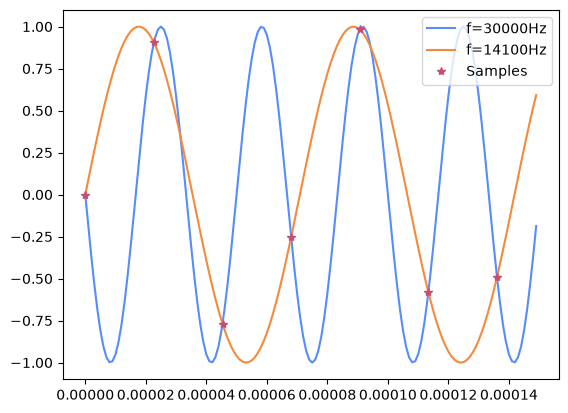

In [3]:
fs = 44100
f1 = 30000
f2 = 14100

n = 150
n_samples = 7

t1 = np.arange(n) / 1e6
s1 = np.sin(2 * np.pi * f1 * np.arange(n) / 1e6)
s2 = np.sin(2 * np.pi * f2 * np.arange(n) / 1e6)

t2 = np.arange(n_samples) / fs
samples = np.sin(2 * np.pi * f2 * np.arange(n_samples) / fs)

plt.plot(t1, -s1, label=f"f={f1}Hz")
plt.plot(t1, s2, label=f"f={f2}Hz")
plt.plot(t2, samples, "*", label="Samples")

plt.legend()
plt.show()

## Окна и утечка спектра

In [4]:
import matplotlib.pyplot as plt
import numpy as np

from dsp_lab.spectrum import dft

In [5]:
N = 64
fs = 8000

f1 = 15 * fs / N
f2 = 15.5 * fs / N

s1 = np.sin(2 * np.pi * f1 * np.arange(N) / fs)
s2 = np.sin(2 * np.pi * f2 * np.arange(N) / fs)

In [6]:


# оконные функции
w_boxcar = np.ones(N)
w_hann = np.hanning(N)
w_hamming = np.hamming(N)
w_blackman = np.blackman(N)

def to_db(x):
    return 20 * np.log10(np.abs(x))

def compare_windows(x, ylimit=(-100, 5), xlimit=(0, N // 2), norm="sum"):

    X_boxcar = dft(x * w_boxcar)
    X_hann = dft(x * w_hann)
    X_hamming = dft(x * w_hamming)
    X_blackman = dft(x * w_blackman)

    if norm == "sum":
        X_boxcar /= np.sum(w_boxcar) * 0.5
        X_hann /= np.sum(w_hann) * 0.5
        X_hamming /= np.sum(w_hamming) * 0.5
        X_blackman /= np.sum(w_blackman) * 0.5
    if norm == "max":
        X_boxcar /= np.max(X_boxcar)
        X_hann /= np.max(X_hann)
        X_hamming /= np.max(X_hamming)
        X_blackman /= np.max(X_blackman)

    plt.figure(figsize=(14, 7))
    plt.plot(to_db(X_boxcar), label="w_boxcar")
    plt.plot(to_db(X_hann), label="w_hann")
    plt.plot(to_db(X_hamming), label="w_hamming")
    plt.plot(to_db(X_blackman), label="w_blackman")

    plt.ylim(*ylimit)
    plt.xlim(*xlimit)
    plt.title(f"Сравнение оконных функций")
    plt.ylabel("Амплитудный спектр, дБ")
    plt.xlabel("Номер бина ДПФ")
    plt.legend()


## Утечка спектра если тон не попадает в бин

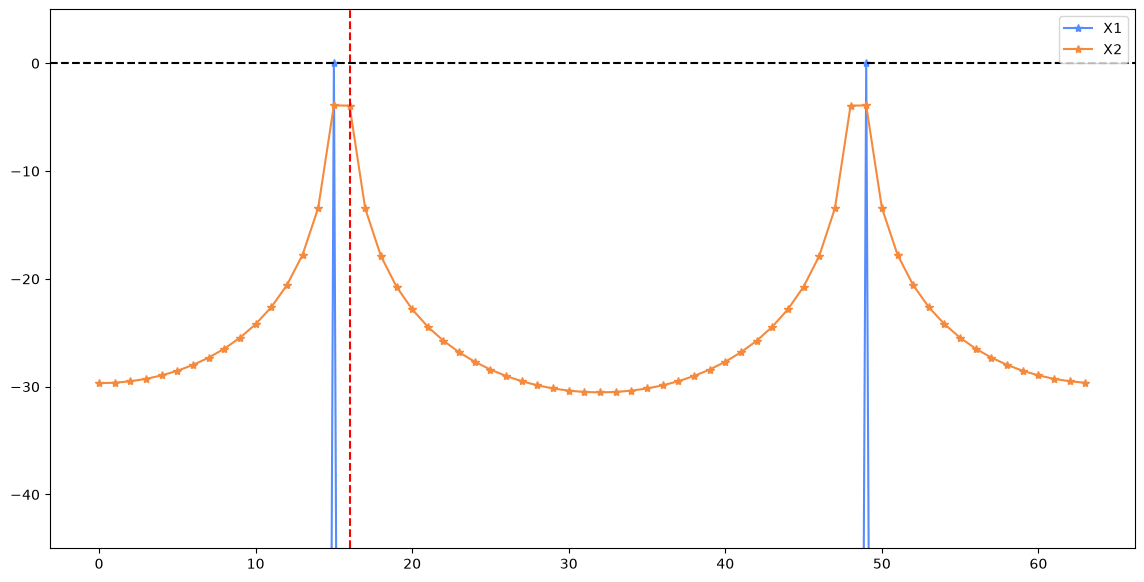

In [7]:
X1_boxcar = 2 * dft(s1 * w_boxcar) / np.sum(w_boxcar)
X2_boxcar = 2 * dft(s2 * w_boxcar) / np.sum(w_boxcar)

plt.figure(figsize=(14, 7))
plt.plot(to_db(X1_boxcar), "-*", label="X1")
plt.plot(to_db(X2_boxcar), "-*", label="X2")
plt.ylim(-45, 5)
plt.axvline(16, color="red", linestyle="dashed")
plt.axhline(0, color="black", linestyle="dashed")
plt.legend()


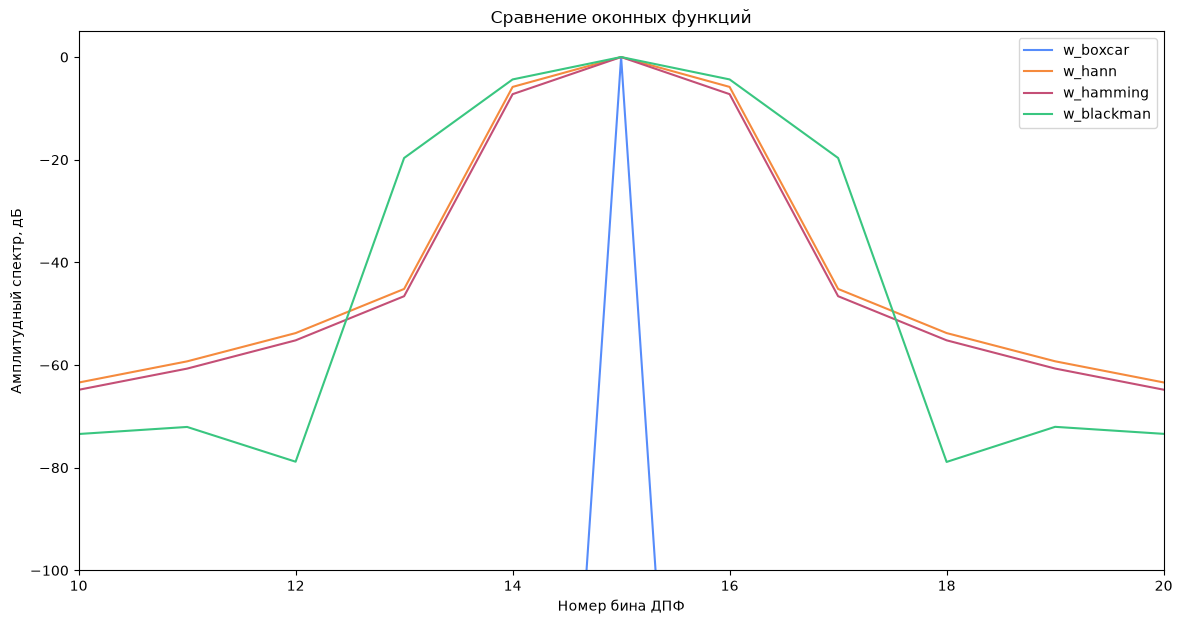

In [8]:
compare_windows(s1, xlimit=(10, 20))


### Уровень боковых лепестков

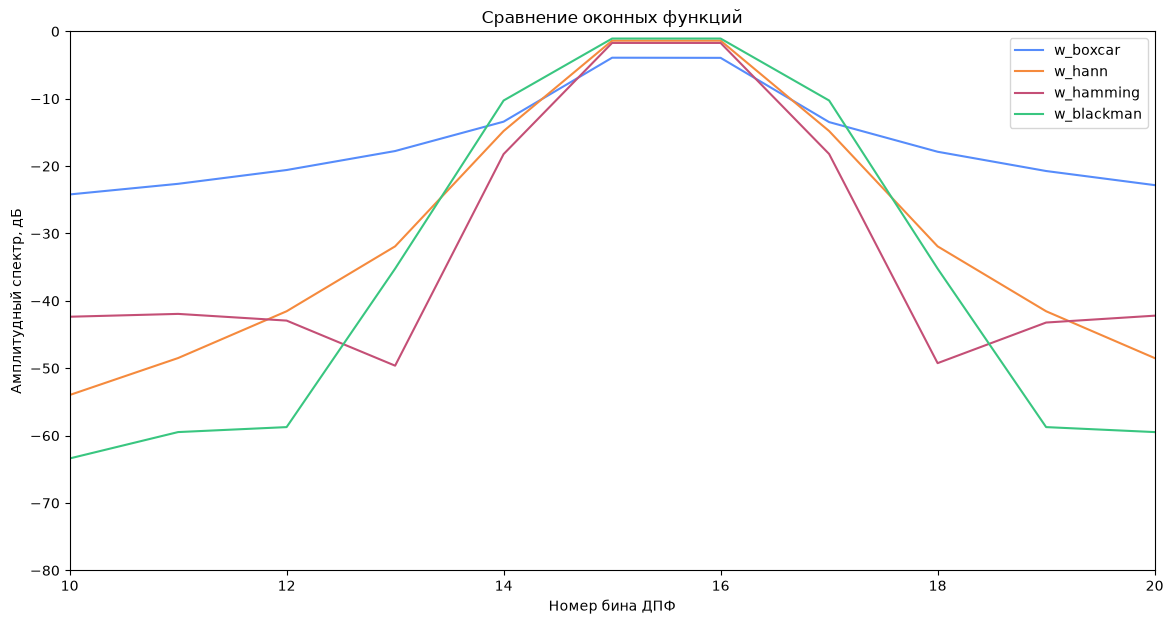

In [9]:

compare_windows(s2, (-80, 0), (10, 20))

## Выводы по окнам и утечке спектра
- Если тон попадает между бинами, то спектр растекается по сеседним бинам, больше всего по ближайшим соседним.
- Ширина лепестка увеличивается в порядке boxcar, hamming, hann, blackman
- При идеальном попадании тона в бин ДПФ, все окна дают одинаковую амплитуду тона
- Если тон не попадает в бин, то амплитуда спектральной составляющей тона различна, в порядке уменьшения: blackman, hann, hamming, boxcar. Разница между blackman и boxcar около 3 дБ
- Уровень боковых лепестков (утечка в дальние бины) падает в порядке: от самых высоких у boxcar (около -24 дБ) до минимальных у blackman (около -63 дБ) — это главный компромисс при выборе окна

## Порядок ДПФ и различение близких частот

In [10]:
from dsp_lab.spectrum import freq_axis

In [11]:
fs = 8000
N = 64
f1 = 10 * fs / N
f2 = 10.6 * fs / N
print(f1, f2, fs / N)

s1 = np.sin(2 * np.pi * f1 * np.arange(N) / fs)
s2 = np.sin(2 * np.pi * f2 * np.arange(N) / fs)
s = s1 + s2

# применение окна
window = np.ones(N)
s = s * window

s4 = np.concatenate([s, np.zeros(3 * N)])
s16 = np.concatenate([s, np.zeros(15 * N)])

# нормировка
s /= np.sum(window)
s4 /= np.sum(window)
s16 /= np.sum(window)

1250.0 1325.0 125.0


сетка частот и спектры

In [12]:
f = freq_axis(N, fs)
f4 = freq_axis(4 * N, fs)
f16 = freq_axis(16 * N, fs)

X = dft(s)
X4 = dft(s4)
X16 = dft(s16)

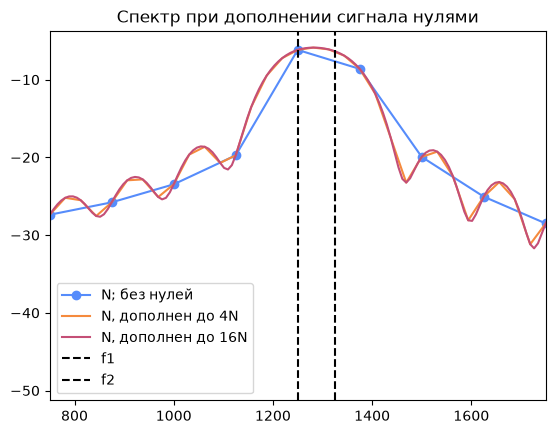

In [13]:
df = fs / N
plt.xlim((f1 - 4*df, f1 + 4*df))

plt.title("Спектр при дополнении сигнала нулями")
plt.plot(f, to_db(X), marker="o", label="N; без нулей")
plt.plot(f4, to_db(X4), label="N, дополнен до 4N")
plt.plot(f16, to_db(X16), label="N, дополнен до 16N")

plt.axvline(f1, linestyle="dashed", color="black", label="f1")
plt.axvline(f2, linestyle="dashed", color="black", label="f2")
plt.legend();

Увеличим длительность ненулевой части сигнала в 4 раза, чтобы повысить разрешение по частоте

In [14]:
N4 = 4 * N
ss1 = np.sin(2 * np.pi * f1 * np.arange(N4) / fs)
ss2 = np.sin(2 * np.pi * f2 * np.arange(N4) / fs)
ss = ss1 + ss2

# применение окна
window4 = np.ones(N4)
ss = ss * window4

ss4 = np.concatenate([ss, np.zeros(3 * N4)])
ss16 = np.concatenate([ss, np.zeros(15 * N4)])

# нормировка
ss /= np.sum(window4)
ss4 /= np.sum(window4)
ss16 /= np.sum(window4)

print(f1, f2, fs / N4)

1250.0 1325.0 31.25


In [15]:
ff = freq_axis(N4, fs)
ff4 = freq_axis(4 * N4, fs)
ff16 = freq_axis(16 * N4, fs)
print(ff16)

XX = dft(ss)
XX4 = dft(ss4)
XX16 = dft(ss16)

[0.00000000e+00 1.95312500e+00 3.90625000e+00 ... 7.99414062e+03
 7.99609375e+03 7.99804688e+03]


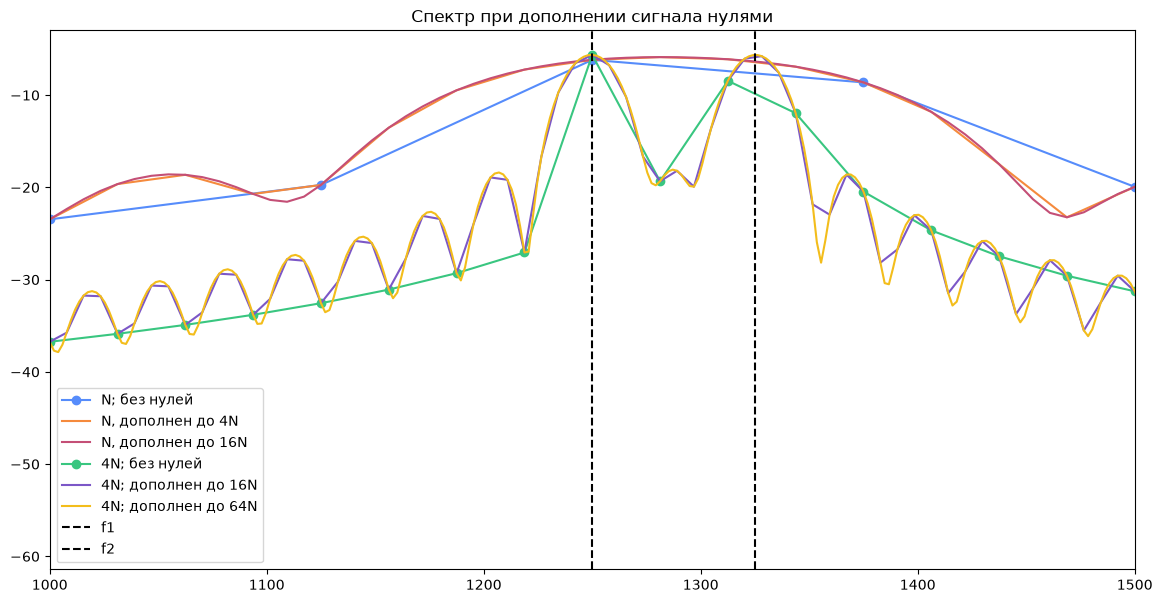

In [16]:
df = fs / N
plt.figure(figsize=(14, 7))
plt.xlim((f1 - 2*df, f1 + 2*df))

plt.title("Спектр при дополнении сигнала нулями")
plt.plot(f, to_db(X), marker="o", label="N; без нулей")
plt.plot(f4, to_db(X4), label="N, дополнен до 4N")
plt.plot(f16, to_db(X16), label="N, дополнен до 16N")

plt.plot(ff, to_db(XX), marker="o", label="4N; без нулей")
plt.plot(ff4, to_db(XX4), label="4N; дополнен до 16N")
plt.plot(ff16, to_db(XX16), label="4N; дополнен до 64N")

plt.axvline(f1, linestyle="dashed", color="black", label="f1")
plt.axvline(f2, linestyle="dashed", color="black", label="f2")
plt.legend();

## Выводы
- дополнение сигнала нулями перед расчетом ДПФ не повышает реальное разрешение по частоте: 2 близких тона останутся смазанными;
- реальное разрешение по частоте увеличивается, если использовать для расчета спектра больше ненулевых отсчетов сигнала при том же fs (т.е. частотное разрешение тем больше, чем длиннее анализируемый фрагмент сигнала);
- дополнение нулями визуально сглаживает спектр.

## Циклическая и линейная свертки

In [17]:
import numpy as np
import matplotlib.pyplot as plt
from dsp_lab.spectrum import circular_convolution, linear_convolution_via_dft

<StemContainer object of 3 artists>

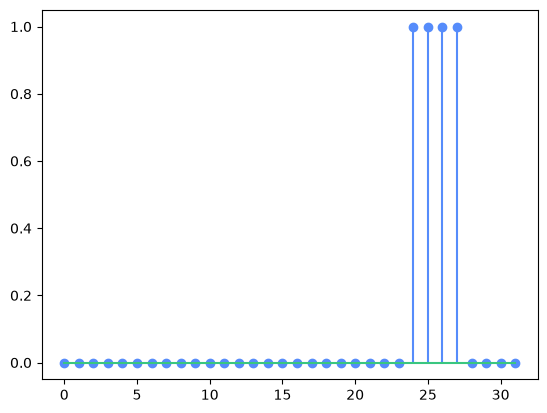

In [18]:
x = np.concatenate([np.zeros(24), np.ones(4), np.zeros(4)])
plt.stem(x)

<StemContainer object of 3 artists>

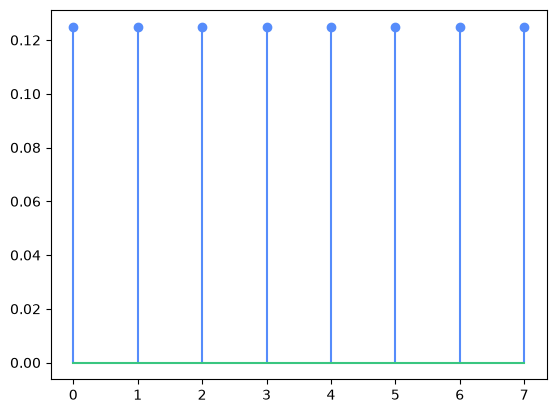

In [19]:
h = np.ones(8) / 8
plt.stem(h)

/home/nikita/PycharmProjects/dsp-comm-labs/.venv/lib/python3.14/site-packages/matplotlib/cbook.py:1811: ComplexWarning: Casting complex values to real discards the imaginary part
  return math.isfinite(val)
/home/nikita/PycharmProjects/dsp-comm-labs/.venv/lib/python3.14/site-packages/matplotlib/cbook.py:1408: ComplexWarning: Casting complex values to real discards the imaginary part
  return np.asanyarray(x, float)


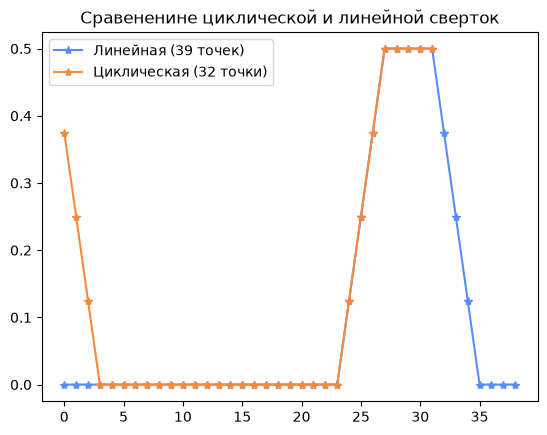

In [20]:
y_circ = circular_convolution(x, h)
y_linear = linear_convolution_via_dft(x, h)

plt.title("Сравененине циклической и линейной сверток")
plt.plot(y_linear, "*-", label=f"Линейная ({len(y_linear)} точек)")
plt.plot(y_circ, "*-", label=f"Циклическая ({len(y_circ)} точки)")
plt.legend();

## Корреляционное обнаружение преамбулы

In [21]:
import numpy as np
import matplotlib.pyplot as plt
from dsp_lab.spectrum import normalized_correlation

Последовательность Баркера-13

Text(0.5, 1.0, 'Последовательность Баркера-13')

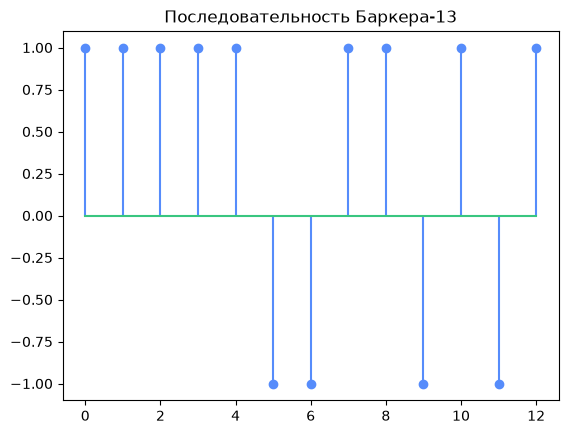

In [55]:
p = np.array([1,1,1,1,1,-1,-1,1,1,-1,1,-1,1])
plt.stem(p)
plt.title("Последовательность Баркера-13")

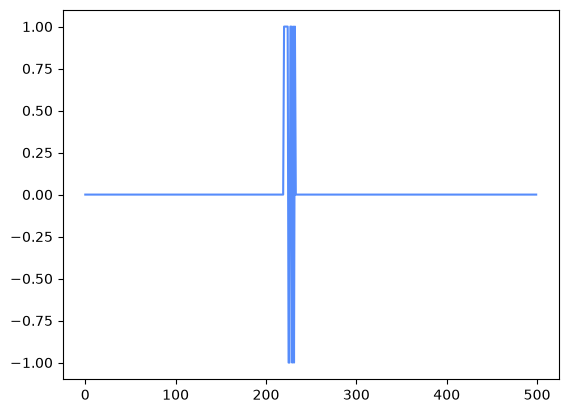

In [81]:
N = 500
p_pos = 220
rng = np.random.default_rng(seed=666)
x = rng.normal(0, 0.0, N)
x[p_pos: p_pos + len(p)] += p
plt.plot(x)

Корреляционный пик равный 1.000 по индексу 220


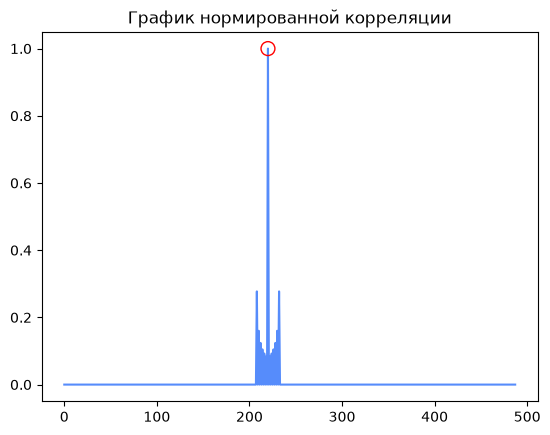

In [83]:
y = normalized_correlation(x, p)
plt.plot(y)
plt.scatter(
    np.argmax(y), np.max(y),
    s=100,               # размер круга (площадь в пунктах^2)
    facecolors='none',   # прозрачная заливка внутри
    edgecolors='red',    # цвет контура
    linewidths=1,        # толщина линии круга
    zorder=5             # поверх остальных линий
)
plt.title("График нормированной корреляции")
print(f"Корреляционный пик равный {np.max(y):.3f} по индексу {np.argmax(y)}")

Положение корреляционного пика совпадает с местом начала преамбулы в сигнале

#### Выясним при каком уровне шума (значении sigma) положение пика нормированной корреляции перестанет совпадать с позицией преамбулы

In [84]:
sigmas = np.linspace(0, 1, 100)
y_max_list = []
pos_list = []

for sigma in sigmas:
    x = rng.normal(0, sigma, N)
    x[p_pos: p_pos + len(p)] += p
    y = normalized_correlation(x, p)

    y_max_list.append(np.max(y))
    pos_list.append(np.argmax(y))


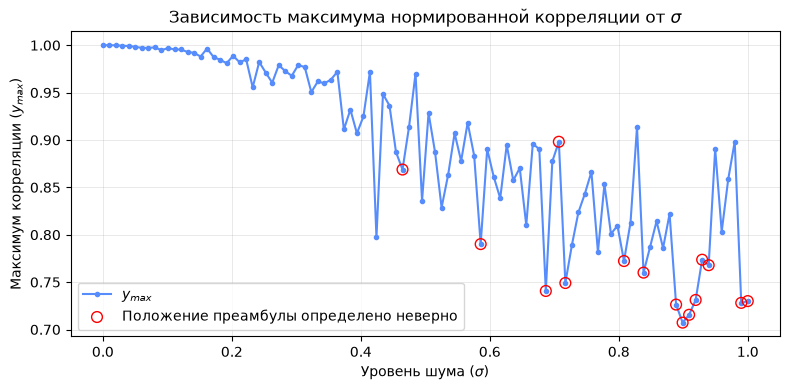

In [85]:
# Построение графика
plt.figure(figsize=(8, 4))
plt.plot(sigmas, y_max_list, ".-", linewidth=1.5, label='$y_{max}$')

# Опционально: выделяем красными точками моменты, когда пик найден не на месте p_pos
pos_arr = np.array(pos_list)
errors = pos_arr != p_pos
if np.any(errors):
    plt.scatter(
        sigmas[errors], np.array(y_max_list)[errors],
        facecolors='none', edgecolors='red', s=60, zorder=5,
        label='Положение преамбулы определено неверно'
    )

plt.xlabel('Уровень шума ($\\sigma$)')
plt.ylabel('Максимум корреляции ($y_{max}$)')
plt.title('Зависимость максимума нормированной корреляции от $\\sigma$')
plt.grid(True, alpha=0.4)
plt.legend()
plt.tight_layout()
plt.show()

### Выполним расчет корреляции с преамбулой, отсчеты которой взяты в обратном порядке (p[::-1])

Корреляционный пик равный 0.668 по индексу 149


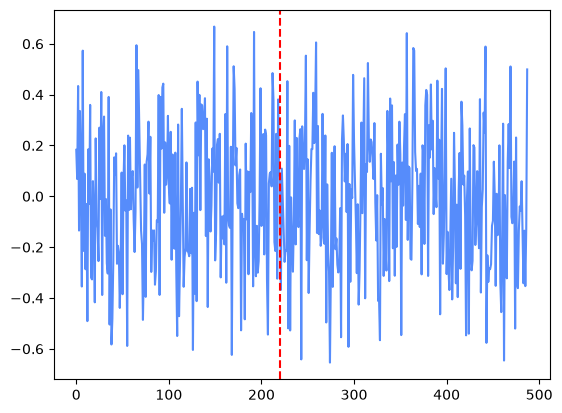

In [54]:
y2 = normalized_correlation(x, p[::-1])
plt.plot(y2)
plt.axvline(p_pos, color="red", linestyle="dashed")
print(f"Корреляционный пик равный {np.max(y2):.3f} по индексу {np.argmax(y2)}")

**Не наблюдаем** корреляционный пик в ожидаемой позиции

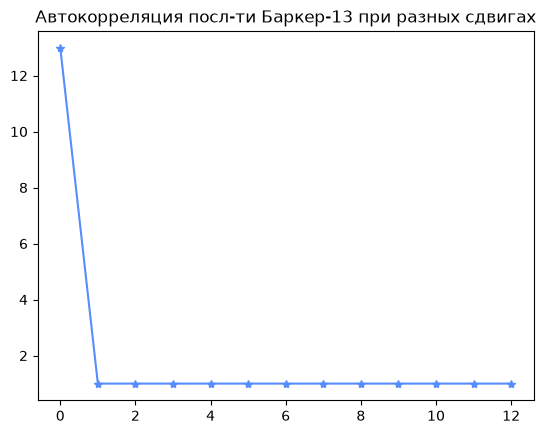

In [96]:
shifts = np.arange(13)
s_list = []
for shift in shifts:
    s = np.sum(p * np.roll(p, shift))
    s_list.append(s)

plt.title("Автокорреляция посл-ти Баркер-13 при разных сдвигах")
plt.plot(shifts, s_list, "*-")